# N3　機台健康預測：預測性維護（第 5 節）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RealKazuya/ai-manufacturing-lab/blob/main/notebooks/N3_predictive_maintenance.ipynb)

〈AI賦能製造：從工廠數據到AI決策〉課程筆記本。資料全部是教學用虛構（恆準精密工業）。

**用法**：由上往下逐格執行（Shift＋Enter）。要改的參數都在「參數」那一格。

In [ ]:
!pip -q install lightgbm==4.7.0

In [1]:
# ── 環境設定（每次開啟先執行這一格）──
import sys, os
IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = os.path.join("..", "data")
DATA = LOCAL_DATA if os.path.isdir(LOCAL_DATA) else "https://raw.githubusercontent.com/RealKazuya/ai-manufacturing-lab/main/data/"
def path(p):
    return os.path.join(DATA, p) if DATA == LOCAL_DATA else DATA + p
print("資料來源：", "本機" if DATA == LOCAL_DATA else "GitHub", "｜Colab：", IN_COLAB)

資料來源： 本機 ｜Colab： False


In [2]:
import matplotlib, matplotlib.pyplot as plt
if IN_COLAB:   # Colab 沒有中文字型，下載思源黑體（約 16 MB）
    import urllib.request, matplotlib.font_manager as fm
    f = "/tmp/NotoSansTC.otf"
    if not os.path.exists(f):
        urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf", f)
    fm.fontManager.addfont(f); matplotlib.rcParams["font.family"] = fm.FontProperties(fname=f).get_name()
else:
    matplotlib.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]
matplotlib.rcParams["axes.unicode_minus"] = False

## 參數

In [3]:
THRESHOLD = 0.4        # 全班選的預警門檻（0.3、0.4、0.5、0.6）
COST = {"抓到": 12, "漏報": 35, "誤報": 2.5}   # 萬元／次

## 讀資料

6 台 VMC 每天的感測摘要（振動 RMS、峰度、最高溫、平均負載），加上維修紀錄。

In [4]:
import pandas as pd, numpy as np
daily = pd.read_csv(path("pdm/vmc_daily_2024_2026.csv"), parse_dates=["date"])
log = pd.read_csv(path("pdm/maintenance_log.csv"), parse_dates=["date"])
log.tail(10)

,date,machine,description,type,downtime_hours
12,2025-10-08,VMC-04,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0
13,2025-11-19,VMC-05,撞機，主軸偏擺校正,非計畫,6.0
14,2025-12-03,VMC-01,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0
15,2026-01-20,VMC-06,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0
16,2026-02-06,全廠,停電,非計畫,4.0
17,2026-03-17,VMC-03,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0
18,2026-04-14,VMC-06,主軸編碼器訊號異常，更換編碼器,非計畫,5.0
19,2026-05-12,VMC-05,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0
20,2026-06-03,VMC-02,換線調機,計畫,3.0
21,2026-07-28,VMC-01,主軸軸承劣化：異音或振動過大，更換主軸軸承,非計畫,20.0


## 人定義：什麼算「軸承劣化」？

只把「主軸軸承劣化」那幾筆當故障。定期保養、換刀、撞機、停電都不算。

In [5]:
failures = log[log.description.str.startswith("主軸軸承劣化")][["machine", "date"]].reset_index(drop=True)
print("軸承劣化停機 %d 次" % len(failures)); failures

軸承劣化停機 14 次


,machine,date
0,VMC-01,2024-02-20
1,VMC-03,2024-04-15
2,VMC-04,2024-06-25
3,VMC-06,2024-09-03
4,VMC-02,2024-11-12
5,VMC-05,2025-01-14
6,VMC-04,2025-03-30
7,VMC-03,2025-06-18
8,VMC-04,2025-10-08
9,VMC-01,2025-12-03


## 共用流程（特徵、標籤、模型、預警事件）

In [6]:
# -*- coding: utf-8 -*-
"""預測性維護的共用流程（特徵、標籤、模型、預警事件）。

m_pdm.py 產生資料與校準時用它；mk_notebooks.py 會把本檔原文放進筆記本 N3，
所以學員在 Colab 跑的流程和產生資料時用的完全一樣。
"""
import numpy as np, pandas as pd

FEATURES = ["vib_ratio", "vib_slope7", "kurt3", "temp_delta", "load_ratio"]

def make_features(daily):
    """每日感測摘要 → 模型特徵（各機台分開算滾動值）。"""
    out = []
    for m, g in daily.sort_values("date").groupby("machine"):
        g = g.copy()
        base_v = g.vib_rms.rolling(60, min_periods=20).median().shift(14)
        base_t = g.temp_max.rolling(60, min_periods=20).median().shift(14)
        base_l = g.load_mean.rolling(60, min_periods=20).median().shift(14)
        g["vib_ratio"] = g.vib_rms / base_v
        g["vib_slope7"] = (g.vib_rms - g.vib_rms.shift(7)) / base_v / 7
        g["kurt3"] = g["kurtosis"].rolling(3, min_periods=1).mean()
        g["temp_delta"] = g.temp_max - base_t
        g["load_ratio"] = g.load_mean / base_l
        out.append(g)
    return pd.concat(out).dropna(subset=FEATURES).reset_index(drop=True)

def add_label(feat, failures, horizon=7):
    """y＝1：未來 1～horizon 天內這台機會發生軸承劣化停機。failures 需有 machine、date 兩欄。"""
    feat = feat.copy(); feat["y"] = 0
    for _, f in failures.iterrows():
        d = (f.date - feat.date).dt.days
        feat.loc[(feat.machine == f.machine) & (d >= 1) & (d <= horizon), "y"] = 1
    return feat

def train_model(X, y, seed=7):
    import lightgbm as lgb
    model = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.03, num_leaves=6, min_child_samples=40, reg_lambda=5.0, monotone_constraints=[1, 1, 1, 1, 0],
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.9,
                               random_state=seed, deterministic=True, n_jobs=1, verbose=-1)
    model.fit(X, y)
    return model

def train_default(X, y, seed=7):
    """不調參數的 LightGBM，用來示範隨機切分與依時間切分的差別。"""
    import lightgbm as lgb
    model = lgb.LGBMClassifier(random_state=seed, deterministic=True, n_jobs=1, verbose=-1)
    model.fit(X, y)
    return model

def alarm_episodes(scores, thr, gap=3):
    """連續（中間空 gap 天以內）超過門檻的日子併成一次預警事件。scores 需有 machine、date、score。"""
    eps = []
    for m, g in scores[scores.score >= thr].sort_values("date").groupby("machine"):
        start = prev = None
        for d in g.date:
            if prev is not None and (d - prev).days > gap:
                eps.append((m, start, prev)); start = None
            start = d if start is None else start
            prev = d
        if start is not None:
            eps.append((m, start, prev))
    return pd.DataFrame(eps, columns=["machine", "start", "end"])

def threshold_table(scores, failures, thresholds, window=14):
    """每個門檻：抓到幾次、漏報幾次、誤報幾次、平均提前天數。
    抓到＝停機前 window 天內有預警；提前天數＝停機日減該次預警的第一天；其餘預警事件算誤報。"""
    rows = []
    for thr in thresholds:
        eps = alarm_episodes(scores, thr)
        used, leads = set(), []
        for _, f in failures.iterrows():
            hit = eps[(eps.machine == f.machine) & (eps.end >= f.date - pd.Timedelta(days=window)) & (eps.start < f.date)]
            if len(hit):
                used |= set(hit.index)
                first = max(hit.start.min(), f.date - pd.Timedelta(days=window))
                leads.append((f.date - first).days)
        rows.append({"門檻": thr, "抓到": len(leads), "漏報": len(failures) - len(leads),
                     "誤報": len(eps) - len(used), "平均提前天數": round(float(np.mean(leads))) if leads else 0})
    return pd.DataFrame(rows)

## 訓練：用 2024-01～2025-08，回測 2025-09～2026-08

In [7]:
feat = add_label(make_features(daily), failures)
train = feat[feat.date <= "2025-08-31"]
model = train_model(train[FEATURES], train.y)
feat["score"] = model.predict_proba(feat[FEATURES])[:, 1]
bt = feat[(feat.date >= "2025-09-01") & (feat.date <= "2026-08-31")]
fbt = failures[(failures.date >= "2025-09-01") & (failures.date <= "2026-08-31")]
table = threshold_table(bt, fbt, [0.3, 0.4, 0.5, 0.6])
table["總成本（萬元）"] = table["抓到"] * COST["抓到"] + table["漏報"] * COST["漏報"] + table["誤報"] * COST["誤報"]
table

,門檻,抓到,漏報,誤報,平均提前天數,總成本（萬元）
0,0.3,6,0,22,9,127.0
1,0.4,6,0,12,7,102.0
2,0.5,5,1,6,7,110.0
3,0.6,4,2,3,6,125.5


## 先猜再跑：隨機切分 vs 依時間切分

同一種模型（LightGBM，不調參數）。隨機切分時，同一次故障前後幾天的資料分在兩邊，模型等於先看過答案。

In [8]:
from sklearn.metrics import f1_score
lab = feat[(feat.date <= "2026-08-31") & ~((feat.machine == "VMC-02") & (feat.date >= "2026-08-17"))]
rs = np.random.default_rng(5).random(len(lab)) < 0.7
m_rand = train_default(lab[rs][FEATURES], lab[rs].y)
m_time = train_default(lab[lab.date <= "2025-08-31"][FEATURES], lab[lab.date <= "2025-08-31"].y)
btl = lab[lab.date >= "2025-09-01"]
print("隨機切分 F1：%.2f" % f1_score(lab[~rs].y, m_rand.predict_proba(lab[~rs][FEATURES])[:, 1] >= 0.5))
print("依時間切分 F1：%.2f" % f1_score(btl.y, m_time.predict_proba(btl[FEATURES])[:, 1] >= 0.5))

隨機切分 F1：0.90
依時間切分 F1：0.71


## 另外兩種做法：固定門檻、異常偵測

In [9]:
from sklearn.ensemble import IsolationForest
fixed = bt[bt.vib_ratio >= 1.5]
iso = IsolationForest(random_state=0, contamination=0.03).fit(train[FEATURES])
bt_iso = bt.assign(anomaly=iso.predict(bt[FEATURES]) == -1)
print("固定門檻（振動是平常的 1.5 倍）警報天數：%d" % len(fixed))
print("IsolationForest 判為異常的天數：%d" % bt_iso.anomaly.sum())

固定門檻（振動是平常的 1.5 倍）警報天數：261
IsolationForest 判為異常的天數：137


## 套用全班的門檻：VMC-02 現在怎樣？

VMC-02 在 2026-09-14 的風險分數：0.73 → 紅燈


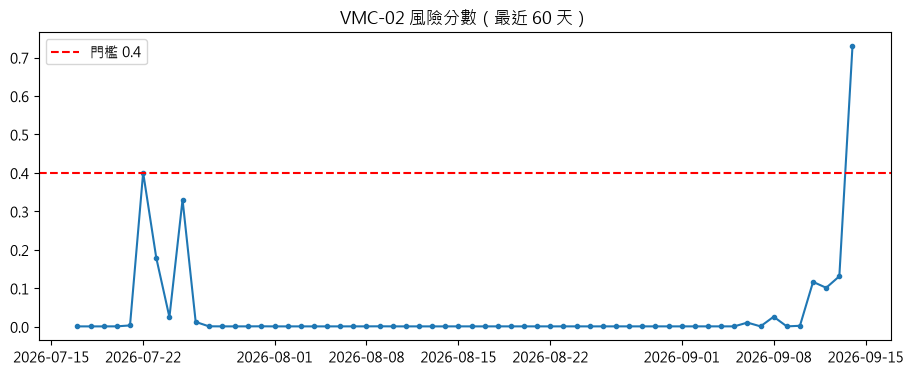

In [10]:
v2 = feat[feat.machine == "VMC-02"].tail(60)
print("VMC-02 在 %s 的風險分數：%.2f → %s" % (v2.date.iloc[-1].date(), v2.score.iloc[-1], "紅燈" if v2.score.iloc[-1] >= THRESHOLD else "正常"))
plt.figure(figsize=(11, 4)); plt.plot(v2.date, v2.score, marker="o", ms=3)
plt.axhline(THRESHOLD, color="red", ls="--", label="門檻 %.1f" % THRESHOLD); plt.legend(); plt.title("VMC-02 風險分數（最近 60 天）"); plt.show()